In [13]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras import Sequential
from tensorflow.keras import layers
from keras.optimizers import Adam
from sklearn.metrics import r2_score

In [2]:
data = pd.read_csv("kc_house_data - kc_house_data.csv")
data= data.drop('date',axis=1)

print(data.head())

           id     price  bedrooms  bathrooms  sqft_living  sqft_lot  floors  \
0  7129300520  221900.0         3       1.00         1180      5650     1.0   
1  6414100192  538000.0         3       2.25         2570      7242     2.0   
2  5631500400  180000.0         2       1.00          770     10000     1.0   
3  2487200875  604000.0         4       3.00         1960      5000     1.0   
4  1954400510  510000.0         3       2.00         1680      8080     1.0   

   waterfront  view  condition  grade  sqft_above  sqft_basement  yr_built  \
0           0     0          3      7      1180.0              0      1955   
1           0     0          3      7      2170.0            400      1951   
2           0     0          3      6       770.0              0      1933   
3           0     0          5      7      1050.0            910      1965   
4           0     0          3      8      1680.0              0      1987   

   yr_renovated  zipcode      lat     long  sqft_living1

In [3]:
data.corr()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
id,1.000000,-0.016797,0.001286,0.005160,-0.012258,-0.132109,0.018525,-0.002721,0.011592,-0.023783,0.008130,-0.010830,-0.005151,0.021380,-0.016907,-0.008224,-0.001891,0.020799,-0.002901,-0.138798
price,-0.016797,1.000000,0.308338,0.525134,0.702044,0.089655,0.256786,0.266331,0.397346,0.036392,0.667463,0.605565,0.323837,0.053982,0.126442,-0.053168,0.306919,0.021571,0.585374,0.082456
bedrooms,0.001286,0.308338,1.000000,0.515884,0.576671,0.031703,0.175429,-0.006582,0.079532,0.028472,0.356967,0.477616,0.303093,0.154178,0.018841,-0.152668,-0.008931,0.129473,0.391638,0.029244
bathrooms,0.005160,0.525134,0.515884,1.000000,0.754665,0.087740,0.500653,0.063744,0.187737,-0.124982,0.664983,0.685363,0.283770,0.506019,0.050739,-0.203866,0.024573,0.223042,0.568634,0.087175
sqft_living,-0.012258,0.702044,0.576671,0.754665,1.000000,0.172826,0.353949,0.103818,0.284611,-0.058753,0.762704,0.876644,0.435043,0.318049,0.055363,-0.199430,0.052529,0.240223,0.756420,0.183286
sqft_lot,-0.132109,0.089655,0.031703,0.087740,0.172826,1.000000,-0.005201,0.021604,0.074710,-0.008958,0.113621,0.183511,0.015286,0.053080,0.007644,-0.129574,-0.085683,0.229521,0.144608,0.718557
floors,0.018525,0.256786,0.175429,0.500653,0.353949,-0.005201,1.000000,0.023698,0.029444,-0.263768,0.458183,0.523899,-0.245705,0.489319,0.006338,-0.059121,0.049614,0.125419,0.279885,-0.011269
waterfront,-0.002721,0.266331,-0.006582,0.063744,0.103818,0.021604,0.023698,1.000000,0.401857,0.016653,0.082775,0.072074,0.080588,-0.026161,0.092885,0.030285,-0.014274,-0.041910,0.086463,0.030703
view,0.011592,0.397346,0.079532,0.187737,0.284611,0.074710,0.029444,0.401857,1.000000,0.045990,0.251321,0.167648,0.276947,-0.053440,0.103917,0.084827,0.006157,-0.078400,0.280439,0.072575
condition,-0.023783,0.036392,0.028472,-0.124982,-0.058753,-0.008958,-0.263768,0.016653,0.045990,1.000000,-0.144674,-0.158206,0.174105,-0.361417,-0.060618,0.003026,-0.014941,-0.106500,-0.092824,-0.003406


In [4]:
price_data = data.corr()['price'].sort_values(ascending=False)
print(price_data)

price            1.000000
sqft_living      0.702044
grade            0.667463
sqft_above       0.605565
sqft_living15    0.585374
bathrooms        0.525134
view             0.397346
sqft_basement    0.323837
bedrooms         0.308338
lat              0.306919
waterfront       0.266331
floors           0.256786
yr_renovated     0.126442
sqft_lot         0.089655
sqft_lot15       0.082456
yr_built         0.053982
condition        0.036392
long             0.021571
id              -0.016797
zipcode         -0.053168
Name: price, dtype: float64


In [5]:
data.isnull().sum()

id               0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       2
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [6]:
data = data.dropna()

In [7]:
data = data.drop('id',axis=1)
data = data.drop('zipcode',axis=1)

x = data.drop('price',axis=1)
y= data['price']

In [9]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42)

x_train = x_train.values.reshape(-1,17)
x_test = x_test.values.reshape(-1,17)
y_train=y_train.values
y_test = y_test.values

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(15127, 17)
(15127,)
(6484, 17)
(6484,)


In [10]:
scalar = MinMaxScaler()
X_train = scalar.fit_transform(x_train)
X_test = scalar.transform(x_test)

print(X_train.max())
print(X_train.min())

1.0000000000000002
0.0


In [11]:
model = Sequential()
model.add(layers.InputLayer((17,)))
model.add(layers.Dense(17,activation='relu'))
model.add(layers.Dense(17,activation='relu'))
model.add(layers.Dense(17,activation='relu'))
model.add(layers.Dense(1,activation='linear'))

model.compile(optimizer=Adam(learning_rate=0.1),loss = 'mean_squared_error')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 17)                  │             306 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 17)                  │             306 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 17)                  │             306 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              18 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 936 (3.66 KB)

 Trainable params: 936 (3.66 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history = model.fit(X_train,y_train,epochs=50,batch_size=128,validation_data=(X_test,y_test))

Epoch 1/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 170597957632.0000 - val_loss: 85194817536.0000
Epoch 2/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 59551088640.0000 - val_loss: 57891790848.0000
Epoch 3/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 45380079616.0000 - val_loss: 49925726208.0000
Epoch 4/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 41205731328.0000 - val_loss: 45118689280.0000
Epoch 5/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 37813305344.0000 - val_loss: 42248900608.0000
Epoch 6/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 36534538240.0000 - val_loss: 40671744000.0000
Epoch 7/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 35262050304.0000 - val_loss: 37175447552.0000
Epoch 8/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 34057754624.0000 - val_loss: 36652486656.0000
Epoch 9/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 33108699136.0000 - val_loss: 35680120832.0000
Epoch 10/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2

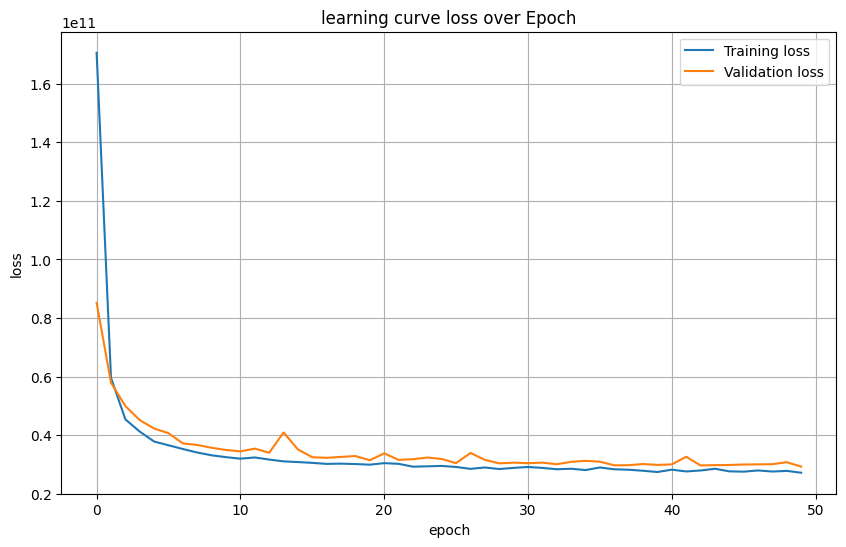

In [14]:
plt.figure(figsize=(10,6))

plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='Validation loss')
plt.title("learning curve loss over Epoch")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
y_pred = model.predict(X_test)
r2_score(y_test,y_pred)

203/203 ━━━━━━━━━━━━━━━━━━━━ 0s 988us/step


0.8070624905839514

In [16]:
sample_index = X_test[0:5,:].reshape(5,-1)

prediction = model.predict(sample_index)
print("Actual value:",y_test[:5])
print("prediction:" ,prediction[:,0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Actual value: [570000. 720001. 267000. 320000. 397000.]
prediction: [613021.9  623210.   200738.53 369552.94 398362.53]


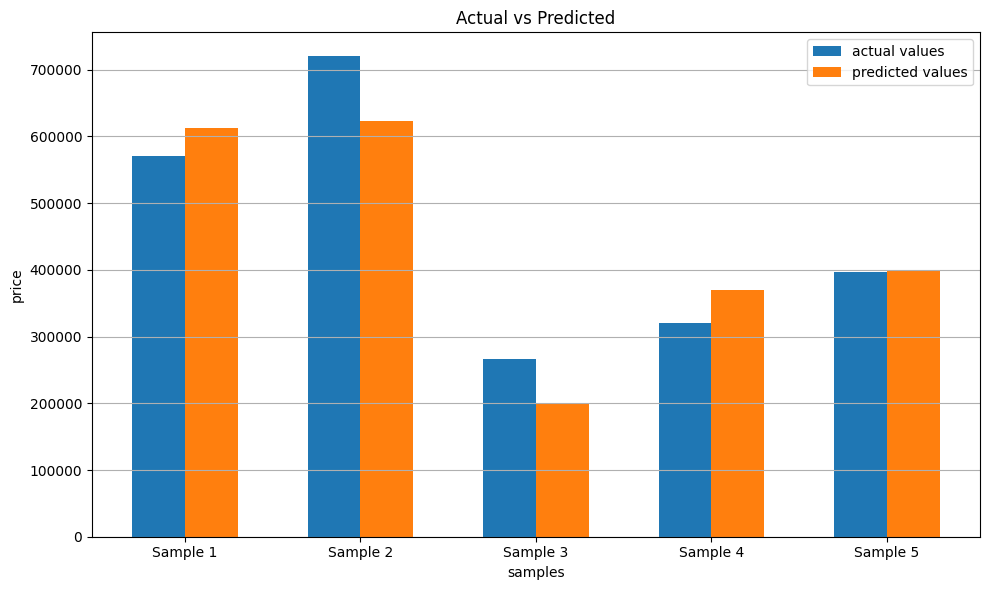

In [23]:
plt.figure(figsize=(10,6))

row_width = 0.3

index = np.arange(len(y_test[:5]))

plt.bar(index,y_test[:5],row_width,label="actual values" )
plt.bar(index+row_width,prediction[:,0],row_width,label="predicted values" )
plt.title("Actual vs Predicted")
plt.xlabel("samples")
plt.ylabel("price")
plt.legend()
plt.xticks(index+row_width/2,[f"Sample {i+1}" for i in range(len(y_test[:5]))])
plt.grid(axis='y')
plt.tight_layout()
plt.show()